# Sesión 4 
Explicación en clase

In [63]:
# librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [64]:
# llamar al archivo spotify2026.csv que esta en data.
spotify = pd.read_csv('data/spotify2026.csv')

In [65]:
spotify.info(    )

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8238 entries, 0 to 8237
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id_usuario                      8235 non-null   float64
 1   genero                          8235 non-null   object 
 2   edad                            8235 non-null   float64
 3   pais                            8235 non-null   object 
 4   tipo_suscripcion                8235 non-null   object 
 5   tiempo_reproduccion_min         8224 non-null   float64
 6   canciones_reproducidas_por_dia  8233 non-null   float64
 7   tasa_de_saltos                  8235 non-null   float64
 8   tipo_dispositivo                8214 non-null   object 
 9   anuncios_escuchados_por_semana  8213 non-null   float64
 10  escucha_sin_conexion            8235 non-null   float64
 11  usuario_cancelado               8235 non-null   float64
dtypes: float64(8), object(4)
memory us

In [66]:
# =============================================================
# BLOQUE 1.1.1 — Importaciones y copia de trabajo
# =============================================================

# Copia de trabajo: el df original 'spotify' queda intacto
df = spotify.copy()

# Chequeo rápido de que se cargó bien
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()

Dimensiones: 8238 filas x 12 columnas


,id_usuario,genero,edad,pais,tipo_suscripcion,tiempo_reproduccion_min,canciones_reproducidas_por_dia,tasa_de_saltos,tipo_dispositivo,anuncios_escuchados_por_semana,escucha_sin_conexion,usuario_cancelado
0,1.0,Femenino,54.0,CA,Gratuito,26.0,23.0,0.20,Escritorio,31.0,0.0,1.0
1,2.0,Otro,33.0,DE,Familiar,141.0,62.0,0.34,Web,0.0,1.0,0.0
2,3.0,Masculino,38.0,AU,Premium,199.0,38.0,0.04,Movil,0.0,1.0,1.0
3,4.0,Femenino,22.0,CA,Estudiante,36.0,2.0,0.31,Movil,0.0,1.0,0.0
4,5.0,Otro,29.0,US,Familiar,250.0,57.0,0.36,Movil,0.0,1.0,1.0


In [67]:
# =============================================================
# BLOQUE 1.1.2 — Perfil por columna
# =============================================================
perfil = pd.DataFrame({
    "dtype":     df.dtypes,
    "nulos":     df.isnull().sum(),
    "Porcentaje_nulos": (df.isnull().mean() * 100).round(2), # porcentaje de nulos
    "Valores únicos":    df.nunique(),
    "ejemplo de dato":   df.iloc[0]
})

print("=== PERFIL POR COLUMNA ===")
perfil

=== PERFIL POR COLUMNA ===


,dtype,nulos,Porcentaje_nulos,Valores únicos,ejemplo de dato
id_usuario,float64,3,0.04,8000,1.0
genero,object,3,0.04,3,Femenino
edad,float64,3,0.04,47,54.0
pais,object,3,0.04,8,CA
tipo_suscripcion,object,3,0.04,4,Gratuito
tiempo_reproduccion_min,float64,14,0.17,290,26.0
canciones_reproducidas_por_dia,float64,5,0.06,99,23.0
tasa_de_saltos,float64,3,0.04,61,0.2
tipo_dispositivo,object,24,0.29,3,Escritorio
anuncios_escuchados_por_semana,float64,25,0.30,46,31.0


Bloque 1.1.3 — Duplicados

In [68]:
# =============================================================
# BLOQUE 1.1.3 — Duplicados
# =============================================================
duplicados_totales = df.duplicated().sum()
duplicados_id      = df.duplicated(subset=["id_usuario"]).sum()

print(f"Filas duplicadas (todas las columnas): {duplicados_totales}")
print(f"IDs de usuario duplicados:            {duplicados_id}")

# Si hay duplicados por id_usuario, mostramos algunos ejemplos
if duplicados_id > 0:
    ids_dup = df[df.duplicated(subset=["id_usuario"], keep=False)] \
                .sort_values("id_usuario")
    print("\nEjemplos de filas con id_usuario repetido:")
    display(ids_dup.head(10))

Filas duplicadas (todas las columnas): 220
IDs de usuario duplicados:            237

Ejemplos de filas con id_usuario repetido:


,id_usuario,genero,edad,pais,tipo_suscripcion,tiempo_reproduccion_min,canciones_reproducidas_por_dia,tasa_de_saltos,tipo_dispositivo,anuncios_escuchados_por_semana,escucha_sin_conexion,usuario_cancelado
15,16.0,Masculino,25.0,FR,Estudiante,230.0,25.0,0.26,Escritorio,0.0,1.0,0.0
41,16.0,Masculino,25.0,FR,Estudiante,230.0,25.0,0.26,Escritorio,0.0,1.0,0.0
16,17.0,Femenino,36.0,DE,Estudiante,181.0,NaN,0.23,Movil,0.0,1.0,0.0
42,17.0,Femenino,36.0,DE,Estudiante,181.0,93.0,0.23,Movil,0.0,1.0,0.0
17,18.0,Masculino,58.0,US,Familiar,120.0,NaN,0.41,Escritorio,0.0,1.0,0.0
43,18.0,Masculino,58.0,US,Familiar,120.0,8.0,0.41,Escritorio,0.0,1.0,0.0
44,19.0,Femenino,34.0,DE,Familiar,160.0,32.0,0.35,Movil,0.0,1.0,0.0
18,19.0,Femenino,34.0,DE,Familiar,160.0,32.0,0.35,Movil,0.0,1.0,0.0
19,20.0,Masculino,35.0,UK,Estudiante,281.0,51.0,0.35,Escritorio,0.0,1.0,0.0
45,20.0,Masculino,35.0,UK,Estudiante,281.0,51.0,0.35,Escritorio,0.0,1.0,0.0


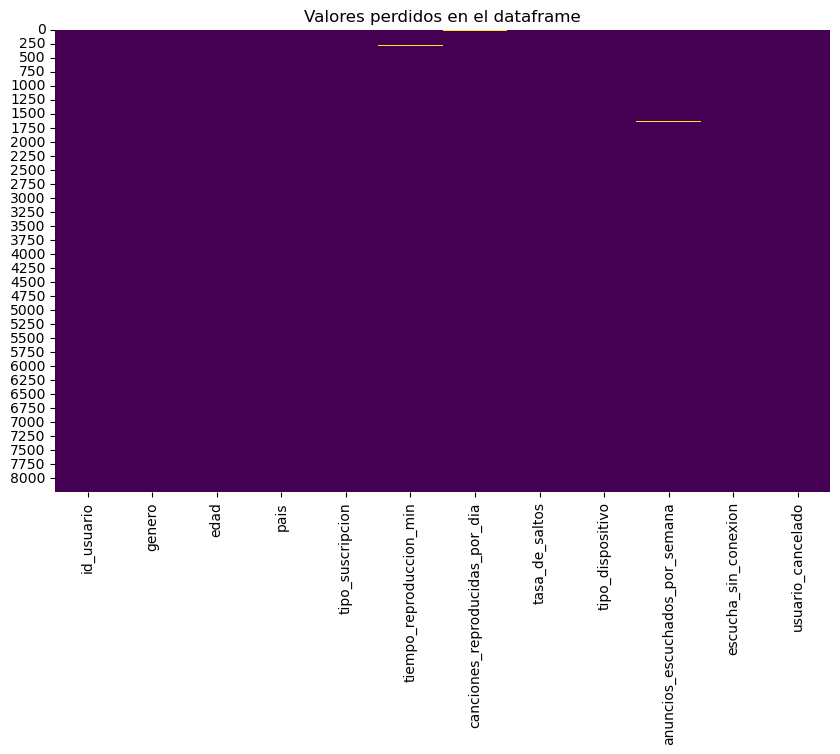

In [69]:
# Valores perdidos de manera grafica
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Valores perdidos en el dataframe")
plt.show()

In [70]:
# Conteo de tipos de datos
df.dtypes.value_counts()

float64    8
object     4
Name: count, dtype: int64

In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8238 entries, 0 to 8237
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id_usuario                      8235 non-null   float64
 1   genero                          8235 non-null   object 
 2   edad                            8235 non-null   float64
 3   pais                            8235 non-null   object 
 4   tipo_suscripcion                8235 non-null   object 
 5   tiempo_reproduccion_min         8224 non-null   float64
 6   canciones_reproducidas_por_dia  8233 non-null   float64
 7   tasa_de_saltos                  8235 non-null   float64
 8   tipo_dispositivo                8214 non-null   object 
 9   anuncios_escuchados_por_semana  8213 non-null   float64
 10  escucha_sin_conexion            8235 non-null   float64
 11  usuario_cancelado               8235 non-null   float64
dtypes: float64(8), object(4)
memory us

In [72]:
# valores únicos de la columan id_usuario en df
df['id_usuario'].nunique()

8000

In [73]:
# Convertimos a tipo 'object' de pandas (preserva NaN de forma explícita)
df["id_usuario"] = df["id_usuario"].astype("string")

In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8238 entries, 0 to 8237
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id_usuario                      8235 non-null   string 
 1   genero                          8235 non-null   object 
 2   edad                            8235 non-null   float64
 3   pais                            8235 non-null   object 
 4   tipo_suscripcion                8235 non-null   object 
 5   tiempo_reproduccion_min         8224 non-null   float64
 6   canciones_reproducidas_por_dia  8233 non-null   float64
 7   tasa_de_saltos                  8235 non-null   float64
 8   tipo_dispositivo                8214 non-null   object 
 9   anuncios_escuchados_por_semana  8213 non-null   float64
 10  escucha_sin_conexion            8235 non-null   float64
 11  usuario_cancelado               8235 non-null   float64
dtypes: float64(7), object(4), string(1

In [75]:
valores_unicos = df.nunique()
valores_unicos


id_usuario                        8000
genero                               3
edad                                47
pais                                 8
tipo_suscripcion                     4
tiempo_reproduccion_min            290
canciones_reproducidas_por_dia      99
tasa_de_saltos                      61
tipo_dispositivo                     3
anuncios_escuchados_por_semana      46
escucha_sin_conexion                 2
usuario_cancelado                    2
dtype: int64

In [76]:
# valores unico de la variable genero
df["genero"].nunique()

3

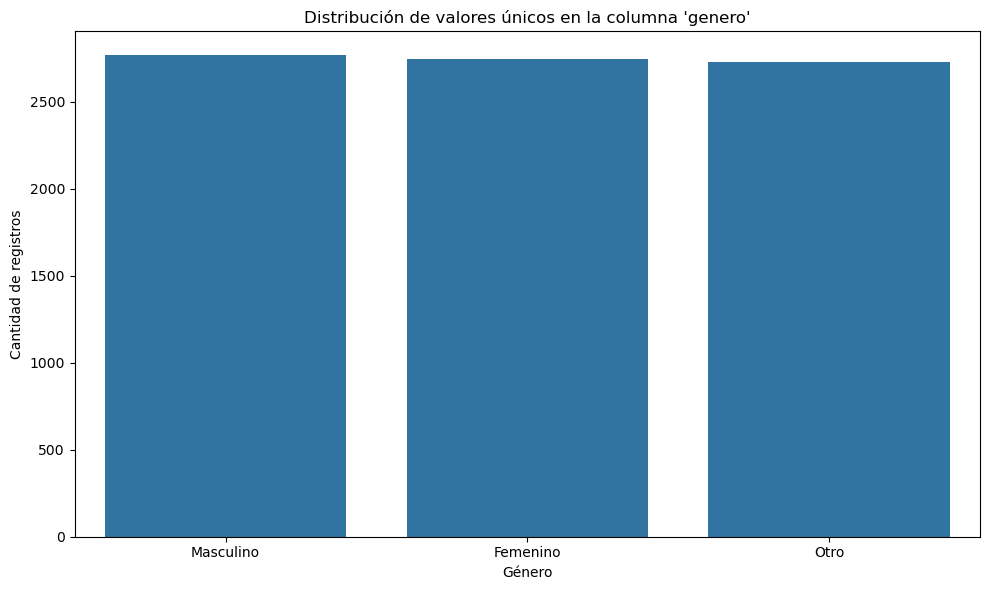

In [77]:
# =============================================================
# BLOQUE — Distribución de la variable 'genero'
# =============================================================
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    x="genero",
    order=df["genero"].value_counts().index
)
plt.title("Distribución de valores únicos en la columna 'genero'")
plt.xlabel("Género")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [78]:
# =============================================================
# BLOQUE — Conteo absoluto de 'genero'
# =============================================================
print("=== CONTEO ABSOLUTO ===")
print(df["genero"].value_counts())

=== CONTEO ABSOLUTO ===
genero
Masculino    2765
Femenino     2745
Otro         2725
Name: count, dtype: int64


In [79]:
# =============================================================
# BLOQUE — Distribución de 'pais'
# =============================================================
tabla_pais = (
    df["pais"]
    .value_counts(dropna=False)
    .rename_axis("pais")
    .reset_index(name="conteo")
)

tabla_pais["porcentaje"] = (tabla_pais["conteo"] / len(df) * 100).round(2)

print(f"=== DISTRIBUCIÓN DE 'pais' ({tabla_pais.shape[0]} categorías) ===")
display(tabla_pais)

=== DISTRIBUCIÓN DE 'pais' (9 categorías) ===


,pais,conteo,porcentaje
0,AU,1075,13.05
1,US,1060,12.87
2,DE,1045,12.69
3,IN,1033,12.54
4,PK,1033,12.54
5,FR,1014,12.31
6,UK,993,12.05
7,CA,982,11.92
8,NaN,3,0.04


In [80]:
# =============================================================
# BLOQUE — Mapear códigos ISO de país a nombres completos
# =============================================================

# Diccionario de mapeo (según los códigos que aparecen en tu dataset)
mapa_paises = {
    "AU": "Australia",
    "US": "Estados Unidos",
    "DE": "Alemania",
    "IN": "India",
    "PK": "Pakistán",
    "FR": "Francia",
    "UK": "Reino Unido",
    "CA": "Canadá",
}

# Aplicar el mapeo (los NaN se conservan automáticamente)
df["pais"] = df["pais"].map(mapa_paises).fillna(df["pais"])

# Verificación
print("=== PAÍSES TRAS EL MAPEO ===")
print(df["pais"].value_counts(dropna=False))

=== PAÍSES TRAS EL MAPEO ===
pais
Australia         1075
Estados Unidos    1060
Alemania          1045
India             1033
Pakistán          1033
Francia           1014
Reino Unido        993
Canadá             982
NaN                  3
Name: count, dtype: int64


In [81]:
df.head()

,id_usuario,genero,edad,pais,tipo_suscripcion,tiempo_reproduccion_min,canciones_reproducidas_por_dia,tasa_de_saltos,tipo_dispositivo,anuncios_escuchados_por_semana,escucha_sin_conexion,usuario_cancelado
0,1.0,Femenino,54.0,Canadá,Gratuito,26.0,23.0,0.20,Escritorio,31.0,0.0,1.0
1,2.0,Otro,33.0,Alemania,Familiar,141.0,62.0,0.34,Web,0.0,1.0,0.0
2,3.0,Masculino,38.0,Australia,Premium,199.0,38.0,0.04,Movil,0.0,1.0,1.0
3,4.0,Femenino,22.0,Canadá,Estudiante,36.0,2.0,0.31,Movil,0.0,1.0,0.0
4,5.0,Otro,29.0,Estados Unidos,Familiar,250.0,57.0,0.36,Movil,0.0,1.0,1.0


# Valores duplicados

In [82]:
# Filas con valores perdidos
valores_perdidos = df[df.isnull().any(axis=1)]
valores_perdidos

,id_usuario,genero,edad,pais,tipo_suscripcion,tiempo_reproduccion_min,canciones_reproducidas_por_dia,tasa_de_saltos,tipo_dispositivo,anuncios_escuchados_por_semana,escucha_sin_conexion,usuario_cancelado
16,17.0,Femenino,36.0,Alemania,Estudiante,181.0,NaN,0.23,Movil,0.0,1.0,0.0
17,18.0,Masculino,58.0,Estados Unidos,Familiar,120.0,NaN,0.41,Escritorio,0.0,1.0,0.0
58,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
60,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
102,92.0,Femenino,41.0,Pakistán,Premium,NaN,85.0,0.22,Web,0.0,1.0,0.0
103,93.0,Femenino,57.0,India,Familiar,NaN,7.0,0.25,Web,0.0,1.0,0.0
104,94.0,Otro,50.0,Reino Unido,Gratuito,NaN,7.0,0.45,Escritorio,44.0,0.0,0.0
105,95.0,Femenino,35.0,Francia,Familiar,NaN,1.0,0.40,Movil,0.0,1.0,0.0
283,261.0,Otro,37.0,Australia,Gratuito,NaN,14.0,0.02,Movil,31.0,0.0,0.0


In [83]:
# Columnas numéricas: Imputar con la media
cols_numericas = df.select_dtypes(include=["number"]).columns
for col in cols_numericas:
    df[col] = df[col].fillna(df[col].mean()) # Imputar con la media

# Columnas categóricas/texto: Imputar con la moda
cols_categoricas = df.select_dtypes(exclude=["number"]).columns
for col in cols_categoricas:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].mode().iloc[0]) # Imputar con la moda

# Verificar que no queden valores perdidos
df.isna().sum()

id_usuario                        0
genero                            0
edad                              0
pais                              0
tipo_suscripcion                  0
tiempo_reproduccion_min           0
canciones_reproducidas_por_dia    0
tasa_de_saltos                    0
tipo_dispositivo                  0
anuncios_escuchados_por_semana    0
escucha_sin_conexion              0
usuario_cancelado                 0
dtype: int64

In [84]:
# filas y columnas.
df.shape

(8238, 12)

In [85]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8238 entries, 0 to 8237
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id_usuario                      8238 non-null   string 
 1   genero                          8238 non-null   object 
 2   edad                            8238 non-null   float64
 3   pais                            8238 non-null   object 
 4   tipo_suscripcion                8238 non-null   object 
 5   tiempo_reproduccion_min         8238 non-null   float64
 6   canciones_reproducidas_por_dia  8238 non-null   float64
 7   tasa_de_saltos                  8238 non-null   float64
 8   tipo_dispositivo                8238 non-null   object 
 9   anuncios_escuchados_por_semana  8238 non-null   float64
 10  escucha_sin_conexion            8238 non-null   float64
 11  usuario_cancelado               8238 non-null   float64
dtypes: float64(7), object(4), string(1

In [86]:
# =============================================================
# BLOQUE CORREGIDO — Conversión óptima de tipos
# =============================================================

# --- 0. Snapshot de memoria antes ---
mem_antes = df.memory_usage(deep=True).sum() / 1024**2
print(f"Memoria antes: {mem_antes:.2f} MB\n")

# --- 1. Categóricas de baja cardinalidad ---
cols_categoricas = ["genero", "pais", "tipo_suscripcion", "tipo_dispositivo"]
for col in cols_categoricas:
    df[col] = df[col].astype("category")

# --- 2. Diagnóstico previo antes de convertir a entero ---
print("=== DIAGNÓSTICO PREVIO ===")
for col in ["edad", "anuncios_escuchados_por_semana"]:
    con_decimales = (df[col] % 1 != 0).sum()
    print(f"{col}: {con_decimales} valores con decimales != 0 "
          f"({con_decimales/len(df)*100:.2f}%)")

# --- 3. Enteras nullable (redondeando primero) ---
df["edad"] = df["edad"].round().astype("Int64")
df["anuncios_escuchados_por_semana"] = (
    df["anuncios_escuchados_por_semana"].round().astype("Int64")
)

# --- 4. Binarias ---
df["escucha_sin_conexion"] = df["escucha_sin_conexion"].astype("int8")
df["usuario_cancelado"]    = df["usuario_cancelado"].astype("int8")

# --- 5. Verificación de tipos ---
print("\n=== TIPOS FINALES ===")
print(df.dtypes)

# --- 6. Verificación de nulos ---
print("\n=== NULOS POR COLUMNA ===")
print(df.isnull().sum())

# --- 7. Snapshot de memoria después ---
mem_despues = df.memory_usage(deep=True).sum() / 1024**2
print(f"\nMemoria después: {mem_despues:.2f} MB")
print(f"Ahorro: {mem_antes - mem_despues:.2f} MB ({(1 - mem_despues/mem_antes)*100:.1f}%)")

Memoria antes: 2.69 MB

=== DIAGNÓSTICO PREVIO ===
edad: 3 valores con decimales != 0 (0.04%)
anuncios_escuchados_por_semana: 25 valores con decimales != 0 (0.30%)

=== TIPOS FINALES ===
id_usuario                        string[python]
genero                                  category
edad                                       Int64
pais                                    category
tipo_suscripcion                        category
tiempo_reproduccion_min                  float64
canciones_reproducidas_por_dia           float64
tasa_de_saltos                           float64
tipo_dispositivo                        category
anuncios_escuchados_por_semana             Int64
escucha_sin_conexion                        int8
usuario_cancelado                           int8
dtype: object

=== NULOS POR COLUMNA ===
id_usuario                        0
genero                            0
edad                              0
pais                              0
tipo_suscripcion                  0
tiem

In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8238 entries, 0 to 8237
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   id_usuario                      8238 non-null   string  
 1   genero                          8238 non-null   category
 2   edad                            8238 non-null   Int64   
 3   pais                            8238 non-null   category
 4   tipo_suscripcion                8238 non-null   category
 5   tiempo_reproduccion_min         8238 non-null   float64 
 6   canciones_reproducidas_por_dia  8238 non-null   float64 
 7   tasa_de_saltos                  8238 non-null   float64 
 8   tipo_dispositivo                8238 non-null   category
 9   anuncios_escuchados_por_semana  8238 non-null   Int64   
 10  escucha_sin_conexion            8238 non-null   int8    
 11  usuario_cancelado               8238 non-null   int8    
dtypes: Int64(2), categor

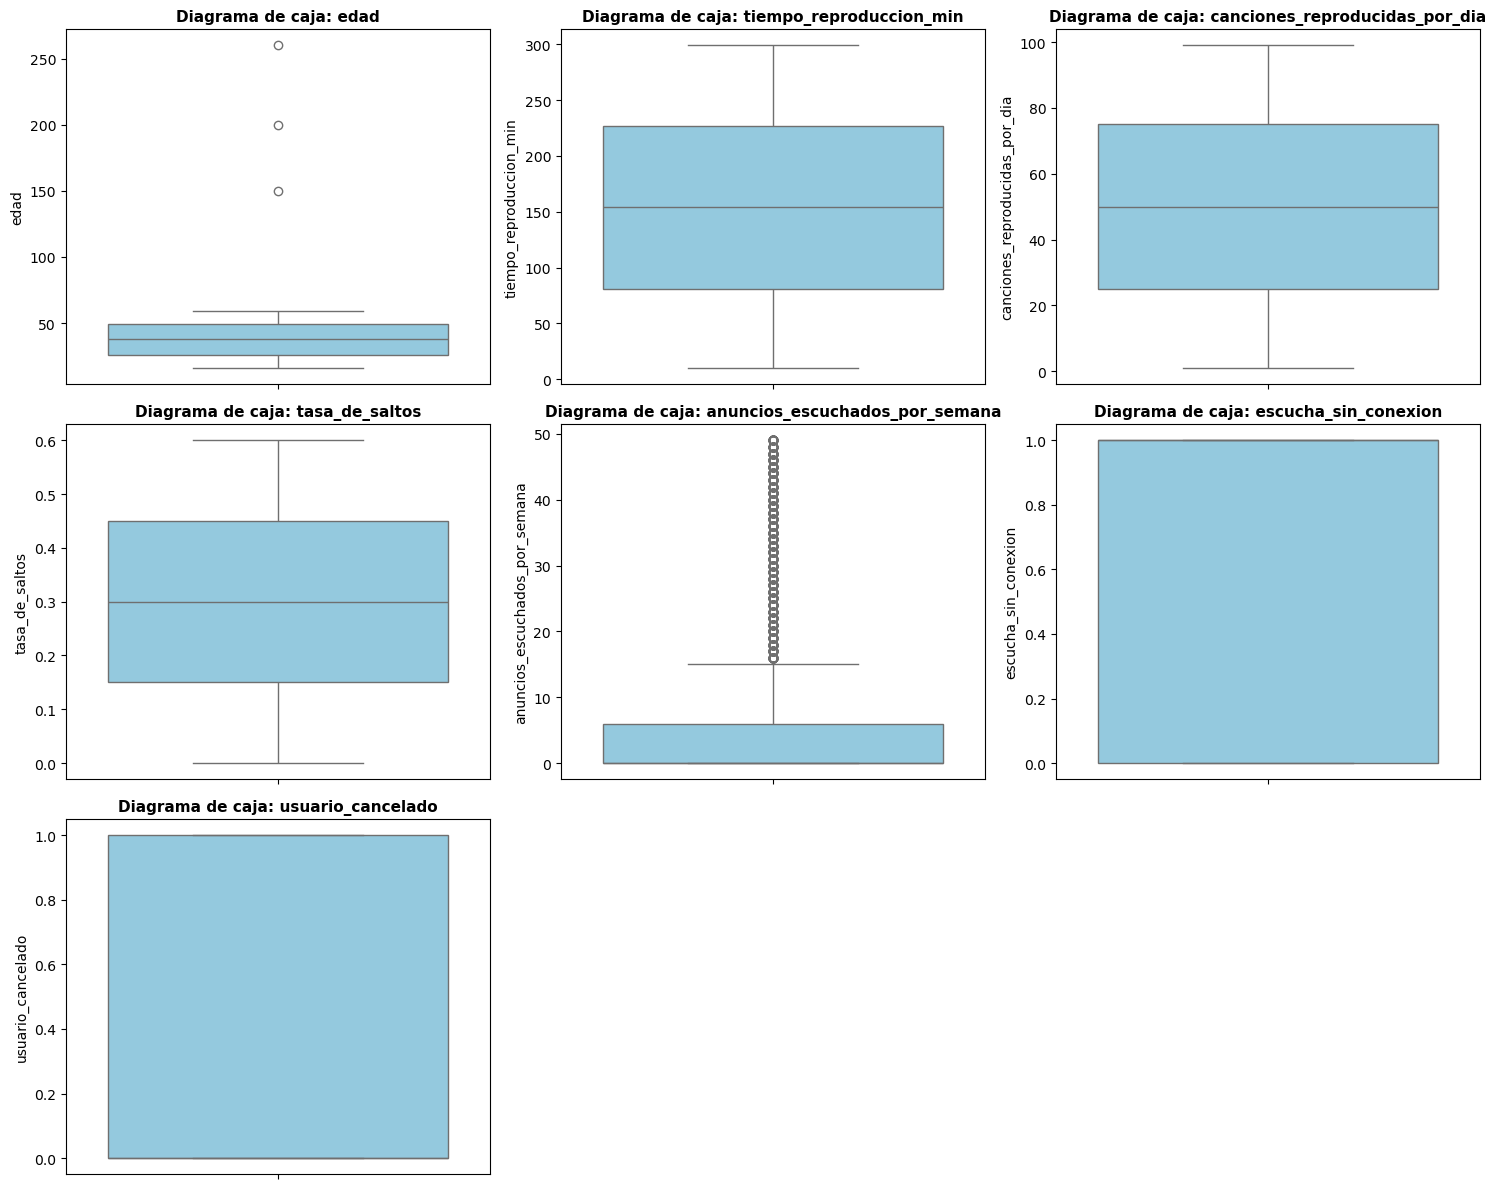

In [88]:

# 1. Seleccionar solo las columnas numéricas
numeric_cols = df.select_dtypes(include=["number"]).columns
num_vars = len(numeric_cols)

# 2. Configurar la cuadrícula de subgráficos (3 columnas por fila)
cols = 3
rows = (num_vars + cols - 1) // cols  # Calcula las filas necesarias dinámicamente

fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
axes = axes.flatten()  # Aplanar la matriz de ejes para iterar fácilmente

# 3. Graficar cada columna de manera independiente
for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i], color="skyblue")
    axes[i].set_title(f"Diagrama de caja: {col}", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("")

# 4. Ocultar cuadros vacíos si la cuadrícula no es exacta
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Valores atípicos

In [89]:
# Estadistica descriptiva de las variables numéricas
descriptiva = df[numeric_cols].describe().T
descriptiva


,count,mean,std,min,25%,50%,75%,max
edad,8238.0,37.732459,13.142389,16.0,26.0,38.0,49.0,260.0
tiempo_reproduccion_min,8238.0,154.055934,83.974205,10.0,81.0,154.0,227.0,299.0
canciones_reproducidas_por_dia,8238.0,50.107616,28.490788,1.0,25.0,50.0,75.0,99.0
tasa_de_saltos,8238.0,0.299319,0.173624,0.0,0.15,0.3,0.45,0.6
anuncios_escuchados_por_semana,8238.0,6.995387,13.64021,0.0,0.0,0.0,6.0,49.0
escucha_sin_conexion,8238.0,0.746298,0.435156,0.0,0.0,1.0,1.0,1.0
usuario_cancelado,8238.0,0.259043,0.438136,0.0,0.0,0.0,1.0,1.0


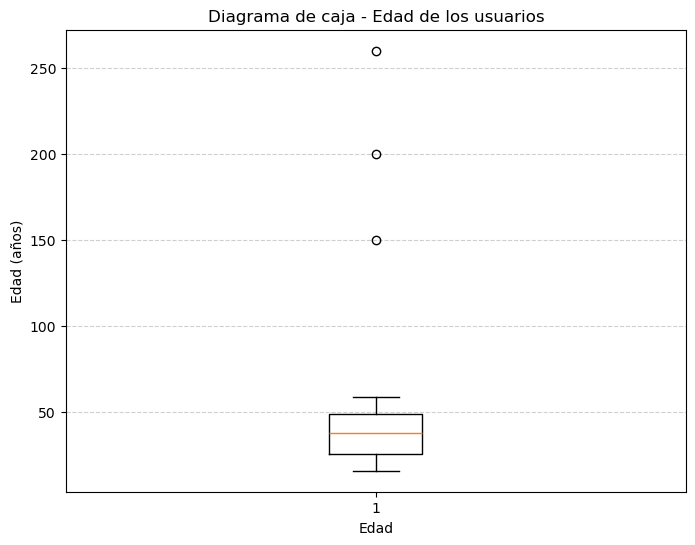

In [90]:
# =============================================================
# BLOQUE — Boxplot de 'edad'
# =============================================================

plt.figure(figsize=(8, 6))
plt.boxplot(df["edad"].dropna())  # dropna por seguridad
plt.title("Diagrama de caja - Edad de los usuarios")
plt.ylabel("Edad (años)")
plt.xlabel("Edad")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

In [91]:
# =============================================================
# BLOQUE — Filas con edades atípicas (outliers por IQR)
# =============================================================

# 1) Calcular límites IQR (los mismos del boxplot anterior)
q1 = df["edad"].quantile(0.25)
q3 = df["edad"].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

print(f"Límite inferior: {limite_inferior}")
print(f"Límite superior: {limite_superior}")

# 2) Filtrar filas fuera de los límites
filas_atipicas = df[
    (df["edad"] < limite_inferior) | (df["edad"] > limite_superior)
]

# 3) Mostrar muestra
print(f"\n=== MUESTRA DE REGISTROS CON EDAD ATÍPICA ({len(filas_atipicas)} filas) ===")
print(filas_atipicas[["id_usuario", "edad"]].head(10))

# 4) Resumen por si son muchos
print(f"\nTotal de outliers: {len(filas_atipicas)} "
      f"({len(filas_atipicas)/len(df)*100:.2f}% del dataset)")
print("\nDistribución de esas edades atípicas:")
print(filas_atipicas["edad"].describe())

Límite inferior: -8.5
Límite superior: 83.5

=== MUESTRA DE REGISTROS CON EDAD ATÍPICA (3 filas) ===
    id_usuario  edad
32        33.0   200
80        70.0   150
146      136.0   260

Total de outliers: 3 (0.04% del dataset)

Distribución de esas edades atípicas:
count           3.0
mean     203.333333
std       55.075705
min           150.0
25%           175.0
50%           200.0
75%           230.0
max           260.0
Name: edad, dtype: Float64


In [92]:
# =============================================================
# BLOQUE — Extremos de edad (los N más bajos y más altos)
# =============================================================
N = 10

print(f"=== {N} EDADES MÁS BAJAS ===")
print(df[["id_usuario", "edad"]].nsmallest(N, "edad"))

print(f"\n=== {N} EDADES MÁS ALTAS ===")
print(df[["id_usuario", "edad"]].nlargest(N, "edad"))

=== 10 EDADES MÁS BAJAS ===
    id_usuario  edad
122      112.0    16
199      177.0    16
201      179.0    16
211      189.0    16
234      212.0    16
323      212.0    16
405      368.0    16
423      386.0    16
453      416.0    16
474      212.0    16

=== 10 EDADES MÁS ALTAS ===
    id_usuario  edad
146      136.0   260
32        33.0   200
80        70.0   150
56        49.0    59
73        63.0    59
84        74.0    59
129      119.0    59
131      121.0    59
217      195.0    59
226      204.0    59


In [94]:
# =============================================================
# BLOQUE — Detección de outliers en 'edad' por método IQR
# =============================================================

# 1) Calcular cuartiles y límites
Q1 = df["edad"].quantile(0.25)
Q3 = df["edad"].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("=== ESTADÍSTICAS IQR ===")
print(f"Q1 (25%):          {Q1}")
print(f"Q3 (75%):          {Q3}")
print(f"IQR:               {IQR}")
print(f"Límite inferior:   {limite_inferior}")
print(f"Límite superior:   {limite_superior}")

# 2) Identificar outliers (sin modificar nada aún)
outliers = df[(df["edad"] < limite_inferior) | (df["edad"] > limite_superior)]
print(f"\n=== OUTLIERS DETECTADOS ===")
print(f"Total outliers: {len(outliers)} ({len(outliers)/len(df)*100:.2f}% del dataset)")

# 3) Ver distribución de esas edades atípicas
print("\nValores únicos de edad en outliers:")
print(outliers["edad"].value_counts().sort_index())

=== ESTADÍSTICAS IQR ===
Q1 (25%):          26.0
Q3 (75%):          49.0
IQR:               23.0
Límite inferior:   -8.5
Límite superior:   83.5

=== OUTLIERS DETECTADOS ===
Total outliers: 3 (0.04% del dataset)

Valores únicos de edad en outliers:
edad
150    1
200    1
260    1
Name: count, dtype: Int64


# Bloque 1 — Cálculo de cuartiles y límites IQR

=== CUARTILES DE 'edad' ===
Q1 (25%):          26.0
Q2 (50%, mediana): 38.0
Q3 (75%):          49.0
IQR (Q3 - Q1):     23.0

Límite inferior:   -8.5
Límite superior:   83.5
=== RESUMEN DE OUTLIERS EN 'edad' ===
Total de filas en el dataset: 8238
Total de outliers detectados: 3 (0.04%)

=== VALORES ÚNICOS DE EDAD EN OUTLIERS ===
edad
150    1
200    1
260    1
Name: count, dtype: Int64

=== MUESTRA DE FILAS OUTLIER ===
    id_usuario  edad
32        33.0   200
80        70.0   150
146      136.0   260
=== RESULTADO DE LA LIMPIEZA ===
Filas antes:    8238
Filas después:  8235
Eliminadas:     3 (0.04%)

Nueva edad mínima: 16
Nueva edad máxima: 59


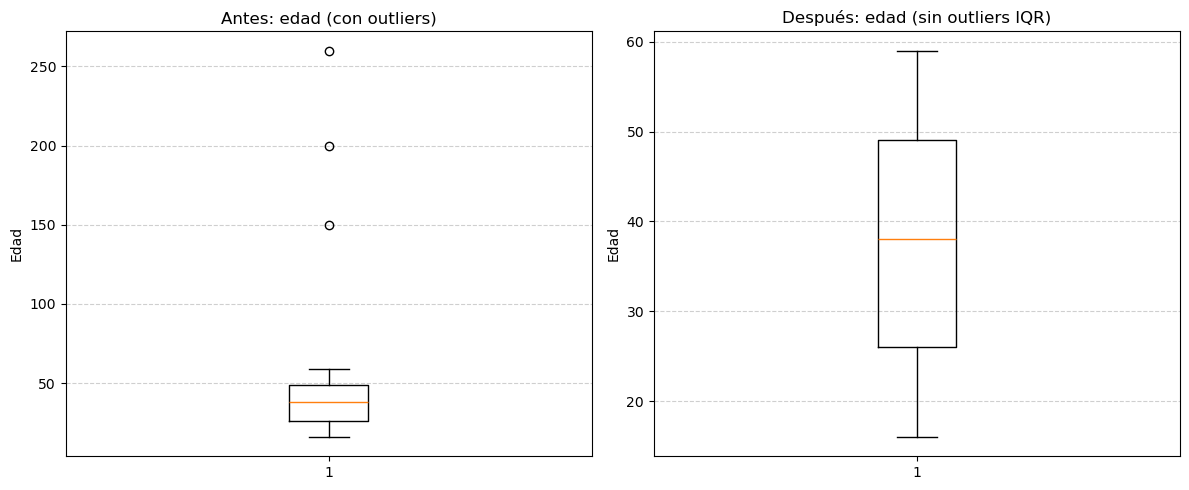

=== NULOS POR COLUMNA ===
id_usuario                        0
genero                            0
edad                              0
pais                              0
tipo_suscripcion                  0
tiempo_reproduccion_min           0
canciones_reproducidas_por_dia    0
tasa_de_saltos                    0
tipo_dispositivo                  0
anuncios_escuchados_por_semana    0
escucha_sin_conexion              0
usuario_cancelado                 0
dtype: int64

=== TIPOS ===
id_usuario                        string[python]
genero                                  category
edad                                       Int64
pais                                    category
tipo_suscripcion                        category
tiempo_reproduccion_min                  float64
canciones_reproducidas_por_dia           float64
tasa_de_saltos                           float64
tipo_dispositivo                        category
anuncios_escuchados_por_semana             Int64
escucha_sin_conexion    

In [95]:
# =============================================================
# BLOQUE 1 — Cálculo de límites IQR para 'edad'
# =============================================================

# Cuartiles
Q1 = df["edad"].quantile(0.25)
Q2 = df["edad"].quantile(0.50)   # mediana
Q3 = df["edad"].quantile(0.75)
IQR = Q3 - Q1

# Límites de Tukey (1.5 × IQR)
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("=== CUARTILES DE 'edad' ===")
print(f"Q1 (25%):          {Q1}")
print(f"Q2 (50%, mediana): {Q2}")
print(f"Q3 (75%):          {Q3}")
print(f"IQR (Q3 - Q1):     {IQR}")
print(f"\nLímite inferior:   {limite_inferior}")
print(f"Límite superior:   {limite_superior}")


# =============================================================
# BLOQUE 2 — Identificar outliers en 'edad'
# =============================================================

# Máscara booleana: True donde la edad es outlier
mask_outliers = (df["edad"] < limite_inferior) | (df["edad"] > limite_superior)

# Filas que son outliers
outliers_df = df[mask_outliers]

print("=== RESUMEN DE OUTLIERS EN 'edad' ===")
print(f"Total de filas en el dataset: {len(df)}")
print(f"Total de outliers detectados: {len(outliers_df)} "
      f"({len(outliers_df)/len(df)*100:.2f}%)")

print("\n=== VALORES ÚNICOS DE EDAD EN OUTLIERS ===")
print(outliers_df["edad"].value_counts().sort_index())

print("\n=== MUESTRA DE FILAS OUTLIER ===")
print(outliers_df[["id_usuario", "edad"]].head(10))

# =============================================================
# BLOQUE 3 — Eliminar outliers de 'edad'
# =============================================================

# Dimensiones antes
filas_antes = len(df)

# Conservar solo filas NO outlier
df = df[~mask_outliers].reset_index(drop=True)

# Dimensiones después
filas_despues = len(df)

print("=== RESULTADO DE LA LIMPIEZA ===")
print(f"Filas antes:    {filas_antes}")
print(f"Filas después:  {filas_despues}")
print(f"Eliminadas:     {filas_antes - filas_despues} "
      f"({(filas_antes - filas_despues)/filas_antes*100:.2f}%)")

print(f"\nNueva edad mínima: {df['edad'].min()}")
print(f"Nueva edad máxima: {df['edad'].max()}")


# =============================================================
# BLOQUE 4 — Comparación visual antes vs después
# =============================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Antes (usamos el df original 'spotify' para no perder la referencia)
axes[0].boxplot(spotify["edad"].dropna())
axes[0].set_title("Antes: edad (con outliers)")
axes[0].set_ylabel("Edad")
axes[0].grid(axis="y", linestyle="--", alpha=0.6)

# Después (df limpio)
axes[1].boxplot(df["edad"].dropna())
axes[1].set_title("Después: edad (sin outliers IQR)")
axes[1].set_ylabel("Edad")
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


# =============================================================
# BLOQUE 5 — Verificación final
# =============================================================
print("=== NULOS POR COLUMNA ===")
print(df.isnull().sum())

print("\n=== TIPOS ===")
print(df.dtypes)

print(f"\n=== DIMENSIONES FINALES ===")
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")

In [97]:
# =============================================================
# VERIFICACIÓN — Estado del dataframe limpio
# =============================================================
print("=== DATAFRAME LIMPIO: df ===")
df.info()

print("\n=== DATAFRAME ORIGINAL: spotify ===")
spotify.info()

=== DATAFRAME LIMPIO: df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8235 entries, 0 to 8234
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   id_usuario                      8235 non-null   string  
 1   genero                          8235 non-null   category
 2   edad                            8235 non-null   Int64   
 3   pais                            8235 non-null   category
 4   tipo_suscripcion                8235 non-null   category
 5   tiempo_reproduccion_min         8235 non-null   float64 
 6   canciones_reproducidas_por_dia  8235 non-null   float64 
 7   tasa_de_saltos                  8235 non-null   float64 
 8   tipo_dispositivo                8235 non-null   category
 9   anuncios_escuchados_por_semana  8235 non-null   Int64   
 10  escucha_sin_conexion            8235 non-null   int8    
 11  usuario_cancelado               8235 non-null   int8 

In [99]:
df.head(5)


,id_usuario,genero,edad,pais,tipo_suscripcion,tiempo_reproduccion_min,canciones_reproducidas_por_dia,tasa_de_saltos,tipo_dispositivo,anuncios_escuchados_por_semana,escucha_sin_conexion,usuario_cancelado
0,1.0,Femenino,54,Canadá,Gratuito,26.0,23.0,0.20,Escritorio,31,0,1
1,2.0,Otro,33,Alemania,Familiar,141.0,62.0,0.34,Web,0,1,0
2,3.0,Masculino,38,Australia,Premium,199.0,38.0,0.04,Movil,0,1,1
3,4.0,Femenino,22,Canadá,Estudiante,36.0,2.0,0.31,Movil,0,1,0
4,5.0,Otro,29,Estados Unidos,Familiar,250.0,57.0,0.36,Movil,0,1,1


In [100]:
df.describe()

,edad,tiempo_reproduccion_min,canciones_reproducidas_por_dia,tasa_de_saltos,anuncios_escuchados_por_semana,escucha_sin_conexion,usuario_cancelado
count,8235.0,8235.000000,8235.000000,8235.000000,8235.0,8235.000000,8235.000000
mean,37.672131,154.018917,50.103283,0.299337,6.996721,0.746327,0.259138
std,12.730015,83.961042,28.493521,0.173634,13.642219,0.435139,0.438188
min,16.0,10.000000,1.000000,0.000000,0.0,0.000000,0.000000
25%,26.0,81.000000,25.000000,0.150000,0.0,0.000000,0.000000
50%,38.0,154.000000,50.000000,0.300000,0.0,1.000000,0.000000
75%,49.0,227.000000,75.000000,0.450000,6.0,1.000000,1.000000
max,59.0,299.000000,99.000000,0.600000,49.0,1.000000,1.000000


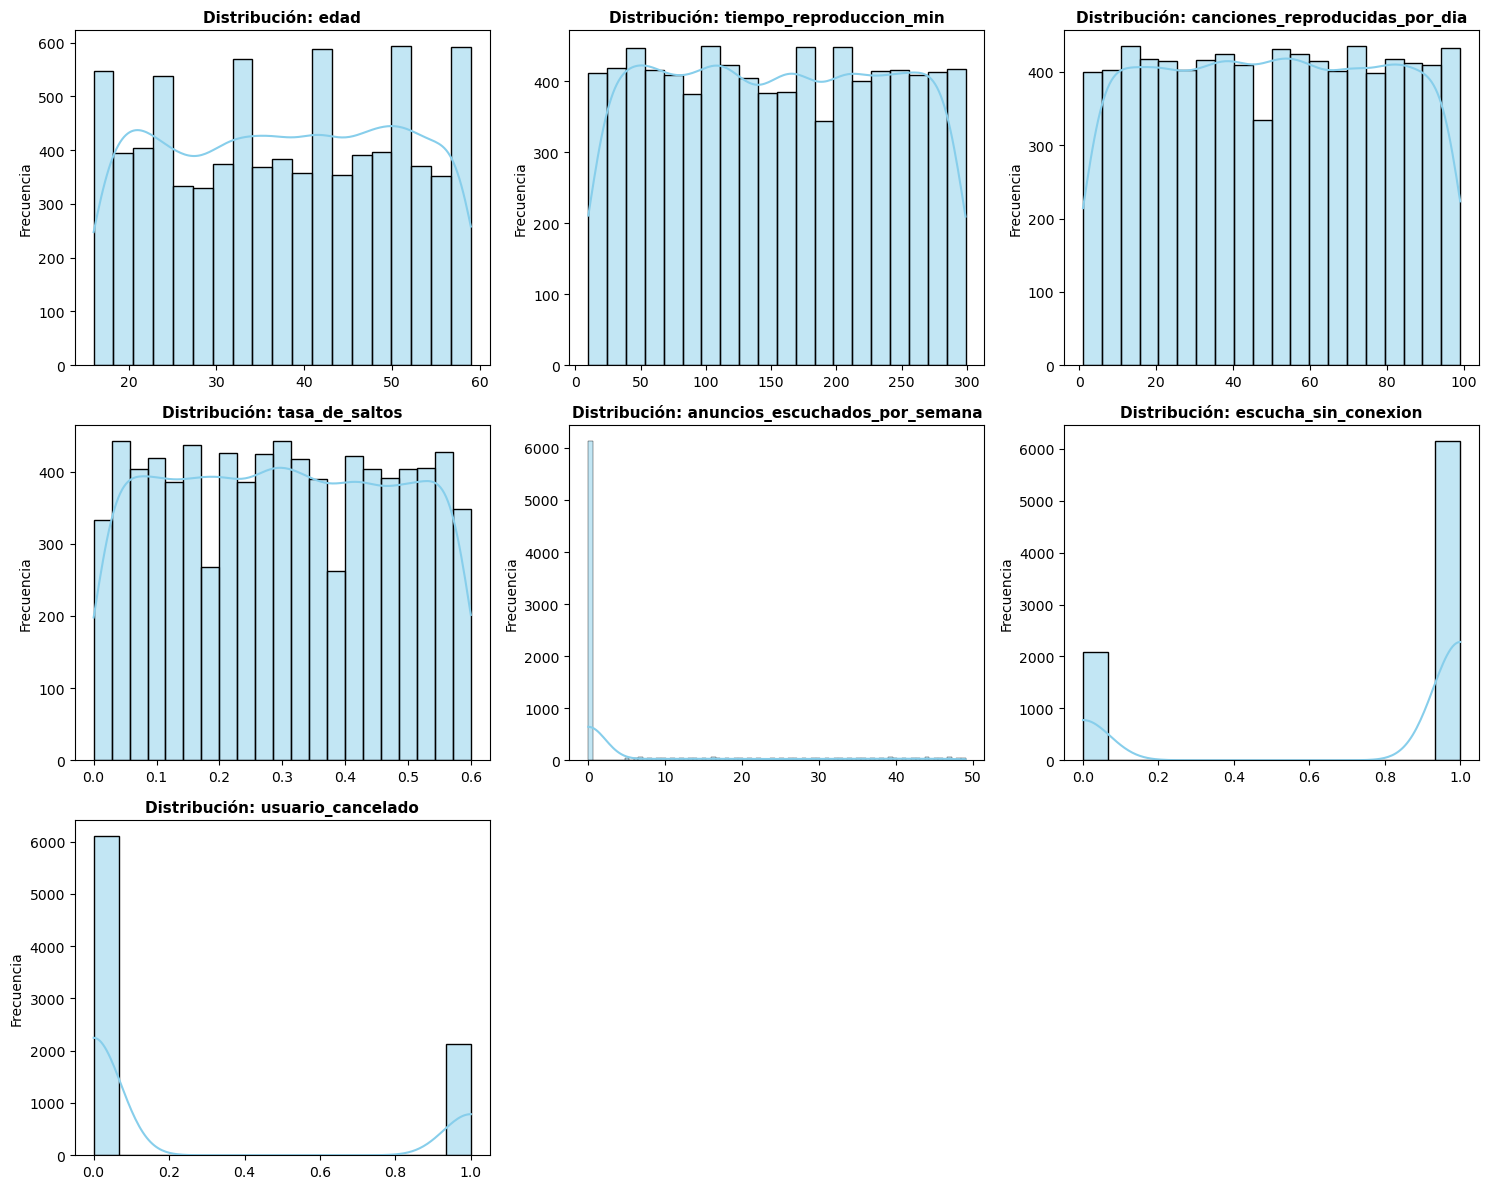

,asimetría,curtosis
edad,-0.027,-1.207
tiempo_reproduccion_min,0.010,-1.212
canciones_reproducidas_por_dia,0.001,-1.194
tasa_de_saltos,0.011,-1.195
anuncios_escuchados_por_semana,1.790,1.771
escucha_sin_conexion,-1.132,-0.718
usuario_cancelado,1.100,-0.791


In [101]:
# =============================================================
# BLOQUE — Distribución de variables numéricas (histograma + KDE)
# =============================================================
numeric_cols = df.select_dtypes(include=["number"]).columns
cols = 3
rows = (len(numeric_cols) + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(df[col].astype("float64"), kde=True, ax=axes[i], color="skyblue")
    axes[i].set_title(f"Distribución: {col}", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frecuencia")

# Eliminar ejes vacíos
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Asimetría y curtosis
forma = pd.DataFrame({
    "asimetría": df[numeric_cols].astype("float64").skew(),
    "curtosis":  df[numeric_cols].astype("float64").kurt()
}).round(3)
forma